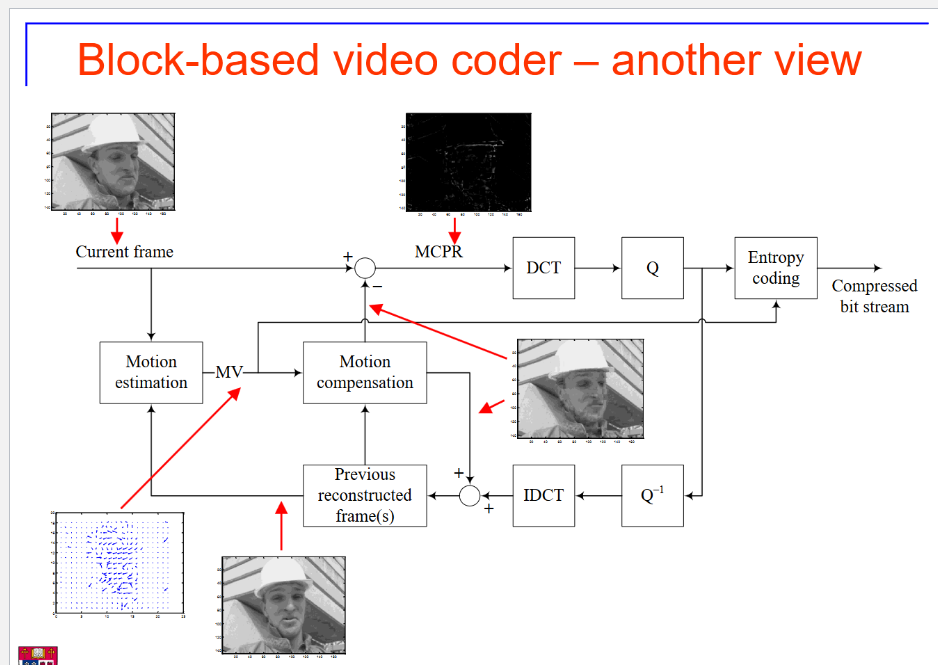 09_Video_coding-1.pdf Slide 8

In [ ]:
# ---- Setup: install deps + make the local .py helpers importable ----
!pip install -q numpy scipy matplotlib pillow


In [ ]:
# ---- Colab only: upload the bvc package files (and the .y input) ----
# Pick __init__.py, __main__.py, codec.py, entropy.py, media.py, metrics.py,
# motion.py, transform.py -- and foreman_qcif.y if you want to encode it.
# .py files go to bvc/, .y files to input/. Skipped when run locally.
import os, sys
try:
    from google.colab import files
except ImportError:
    print("Not in Colab - using the local files.")
else:
    os.makedirs("bvc", exist_ok=True)
    os.makedirs("input", exist_ok=True)
    os.makedirs("output", exist_ok=True)
    uploaded = files.upload()
    for name, data in uploaded.items():
        dest = os.path.join("input" if name.endswith(".y") else "bvc", name)
        with open(dest, "wb") as f:
            f.write(data)
        os.remove(name)              # files.upload() also saves a copy in cwd
        print(f"saved {dest} ({len(data)} bytes)")

In [ ]:
# ---- Make the bvc package importable and import the codec pieces ----
import os, sys

# Locally this notebook sits inside bvc/, so the package's parent folder (FP) goes on
# sys.path; in Colab the files were uploaded to ./bvc, so the working dir goes on it.
inside_pkg = os.path.isfile("codec.py") and os.path.isfile("__main__.py")
root = os.path.dirname(os.getcwd()) if inside_pkg else os.getcwd()
if root not in sys.path:
    sys.path.insert(0, root)

from bvc.transform import dct2, idct2, matlab_round          # 8x8 DCT, MATLAB round
from bvc.entropy import enc_arith                            # arithmetic coder -> .bit file
from bvc.media import read_Yframe, write_Yframe              # raw .y frame I/O
from bvc.motion import motion_estimation, mc_prediction      # ME / MC
from bvc.__main__ import main                                # same as `python -m bvc ...`

# Input clip: ./input in Colab, otherwise the copy in "basic colab setup/input"
INFILE = os.path.abspath("input/foreman_qcif.y")
if not os.path.exists(INFILE):
    INFILE = os.path.abspath(os.path.join("basic colab setup", "input", "foreman_qcif.y"))

import numpy as np
import matplotlib.pyplot as plt
print("Setup complete. bvc imported from", root)
print("Input clip:", INFILE, "exists" if os.path.exists(INFILE) else "MISSING")

In [ ]:
# ---- Block-based video coder: the loop from the slide above ----
#   Current frame -(+)-> MCPR -> DCT -> Q -> Entropy coding -> compressed bit stream
#   Q -> Q^-1 -> IDCT -(+ prediction)-> Previous reconstructed frame(s)
#   Previous reconstructed + Current -> Motion estimation -> MV -> Motion compensation -> prediction
#   MV -> Entropy coding
import os, csv, pickle
import numpy as np
import matplotlib.pyplot as plt
# dct2/idct2/matlab_round, enc_arith, read_Yframe/write_Yframe and ME/MC
# come from the bvc package (imported in the setup cell)

H, W = 144, 176                  # QCIF luma
STEP = 16                        # Q step size
BLK, SR = 16, 7                  # motion estimation block size, search range
SHOW_FRAME = 50                  # frame whose signals get plotted like the slide
infile = INFILE
out_root = os.path.abspath("output/dct_frames")
os.makedirs(out_root, exist_ok=True)
recon_file = os.path.join(out_root, "foreman_recon.y")
if os.path.exists(recon_file):
    os.remove(recon_file)        # write_Yframe appends
n_frames = os.path.getsize(infile) // (H * W)


def entropy_code(data, name, k):
    """Entropy coding block: arithmetic-code an integer array with enc_arith."""
    data = np.asarray(data).astype(np.int64).ravel()
    message_int = data - data.min() + 1                          # symbols must be >= 1
    counts = np.maximum(np.bincount(message_int)[1:], 1).tolist()
    frame_dir = os.path.join(out_root, f"frame_{k:03d}")
    os.makedirs(frame_dir, exist_ok=True)
    histfile = os.path.join(frame_dir, f"{name}_hist.pkl")
    with open(histfile, "wb") as f:
        pickle.dump(counts, f)
    return enc_arith(message_int.tolist(), histfile, os.path.join(frame_dir, f"{name}.bit"))


prev_recon = None                # "Previous reconstructed frame(s)"
bits_res, bits_mv, psnr = [], [], []
snap = None
for k in range(1, n_frames + 1):
    curr = read_Yframe(infile, H, W, k)                          # Current frame

    # Motion estimation -> MV -> Motion compensation -> prediction; MCPR = current - prediction
    if prev_recon is None:       # first frame: no reference yet, predict mid-gray
        mvx = np.zeros((H // BLK, W // BLK), dtype=np.int32)
        mvy = np.zeros_like(mvx)
        pred = np.full((H, W), 128.0)
        mcpr = curr - pred
    else:
        mvx, mvy = motion_estimation(prev_recon, curr, BLK, BLK, SR)
        mcpr, pred = mc_prediction(prev_recon, curr, mvx, mvy)

    # DCT -> Q (8x8 blocks), then Q^-1 -> IDCT on the same blocks
    q = np.zeros((H, W))
    res_rec = np.zeros((H, W))
    for i in range(0, H, 8):
        for j in range(0, W, 8):
            q[i:i+8, j:j+8] = matlab_round(dct2(mcpr[i:i+8, j:j+8]) / STEP)
            res_rec[i:i+8, j:j+8] = idct2(q[i:i+8, j:j+8] * STEP)

    # Entropy coding: quantized coefficients + motion vectors -> compressed bit stream
    bits_res.append(entropy_code(q, "res", k))
    bits_mv.append(entropy_code(np.concatenate([mvx.ravel(), mvy.ravel()]), "mv", k))

    # IDCT output + prediction -> reconstructed frame, the reference for the next frame
    recon = np.clip(np.round(pred + res_rec), 0, 255)
    write_Yframe(recon, recon_file)

    if k == min(SHOW_FRAME, n_frames):
        snap = dict(k=k, curr=curr, mcpr=mcpr, mvx=mvx, mvy=mvy, pred=pred, prev=prev_recon)
    prev_recon = recon

    psnr.append(10 * np.log10(255 ** 2 / np.mean((curr - recon) ** 2)))
    if k % 50 == 0 or k == n_frames:
        print(f"frame {k}/{n_frames}: {bits_res[-1]} + {bits_mv[-1]} bits, PSNR {psnr[-1]:.2f} dB")

with open(os.path.join(out_root, "bits_per_frame.csv"), "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["frame", "bits_residual", "bits_mv", "psnr_db"])
    wr.writerows(zip(range(1, n_frames + 1), bits_res, bits_mv, psnr))

total = sum(bits_res) + sum(bits_mv)
print(f"Total {total} bits ({sum(bits_mv)} for MVs), avg {total / n_frames:.0f} bits/frame, "
      f"{total / (n_frames * H * W):.3f} bpp, avg PSNR {np.mean(psnr):.2f} dB, STEP {STEP}")

# ---- The pictures on the slide, for one frame ----
s = snap
fig, ax = plt.subplots(1, 5, figsize=(20, 3.6))
ax[0].imshow(s["curr"], cmap="gray", vmin=0, vmax=255); ax[0].set_title(f"Current frame ({s['k']})")
ax[1].imshow(np.abs(s["mcpr"]), cmap="gray", vmin=0, vmax=255); ax[1].set_title("MCPR")
ys, xs = np.mgrid[0:s["mvx"].shape[0], 0:s["mvx"].shape[1]] * BLK + BLK // 2   # block centres (pixels)
ax[2].quiver(xs, ys, s["mvx"], s["mvy"], color="b", angles="xy", scale_units="xy", scale=1)
ax[2].set_xlim(0, W); ax[2].set_ylim(H, 0)
ax[2].set_aspect("equal"); ax[2].set_title("MV")
ax[3].imshow(s["pred"], cmap="gray", vmin=0, vmax=255); ax[3].set_title("Motion compensation (prediction)")
ax[4].imshow(s["prev"] if s["prev"] is not None else s["pred"], cmap="gray", vmin=0, vmax=255)
ax[4].set_title("Previous reconstructed frame")
plt.tight_layout()
plt.show()

In [ ]:
# ---- Block-based video coder (09_Video_coding slide 8) ----
import pickle

H, W = 144, 176          # QCIF luma
STEP = 16                # Q step size (bigger = fewer bits, lower quality)
BLK, SR = 16, 7          # motion estimation block size and search range
infile = INFILE
out_dir = os.path.abspath("output/hybrid")
os.makedirs(out_dir, exist_ok=True)
recon_file = os.path.join(out_dir, "foreman_recon.y")
if os.path.exists(recon_file):
    os.remove(recon_file)                      # write_Yframe appends
n_frames = os.path.getsize(infile) // (H * W)

prev_recon = None                              # "Previous reconstructed frame(s)"
bits_res, bits_mv, psnr = [], [], []
for k in range(1, n_frames + 1):
    curr = read_Yframe(infile, H, W, k)        # "Current frame"

    # Motion estimation -> MV, motion compensation -> prediction, MCPR = curr - pred
    if prev_recon is None:                     # frame 1 has no reference: predict mid-gray
        mvx = np.zeros((H // BLK, W // BLK), dtype=np.int32)
        mvy = np.zeros_like(mvx)
        pred = np.full((H, W), 128.0)
        mcpr = curr - pred
    else:
        mvx, mvy = motion_estimation(prev_recon, curr, BLK, BLK, SR)
        mcpr, pred = mc_prediction(prev_recon, curr, mvx, mvy)

    # DCT -> Q (8x8 blocks)
    q = np.zeros((H, W))
    for i in range(0, H, 8):
        for j in range(0, W, 8):
            q[i:i+8, j:j+8] = matlab_round(dct2(mcpr[i:i+8, j:j+8]) / STEP)

    # Entropy coding: quantized MCPR and the motion vectors -> compressed bit stream
    for name, data, bits in [("res", q, bits_res),
                             ("mv", np.concatenate([mvx.ravel(), mvy.ravel()]), bits_mv)]:
        data = data.astype(np.int64).ravel()
        message_int = data - data.min() + 1                # symbols must be >= 1
        counts = np.maximum(np.bincount(message_int)[1:], 1).tolist()
        histfile = os.path.join(out_dir, f"{name}_hist_{k:03d}.pkl")
        with open(histfile, "wb") as f:
            pickle.dump(counts, f)
        outfile = os.path.join(out_dir, f"{name}_{k:03d}.bit")
        bits.append(enc_arith(message_int.tolist(), histfile, outfile))

    # Q^-1 -> IDCT -> + prediction = reconstructed frame (next frame's reference)
    res_rec = np.zeros((H, W))
    for i in range(0, H, 8):
        for j in range(0, W, 8):
            res_rec[i:i+8, j:j+8] = idct2(q[i:i+8, j:j+8] * STEP)
    recon = np.clip(np.round(pred + res_rec), 0, 255)
    write_Yframe(recon, recon_file)
    prev_recon = recon

    psnr.append(10 * np.log10(255 ** 2 / np.mean((curr - recon) ** 2)))
    if k % 50 == 0 or k == n_frames:
        print(f"frame {k}/{n_frames}: {bits_res[-1]} + {bits_mv[-1]} bits, "
              f"PSNR {psnr[-1]:.2f} dB")

total = sum(bits_res) + sum(bits_mv)
print(f"Total {total} bits ({sum(bits_mv)} for MVs), "
      f"{total / (n_frames * H * W):.3f} bpp, avg PSNR {np.mean(psnr):.2f} dB")

In [ ]:
# ---- Bjøntegaard Delta metrics: hybrid (ME/MC + DCT) vs intra DCT ----
# Runs bvc's `benchmark` command through main() -- the same as running, from the FP folder:
#   python -m bvc benchmark "bvc/basic colab setup/input/foreman_qcif.y" --frames 30
# It sweeps the rate points for each codec, prints them, computes BD-rate and BD-PSNR
# (cubic fit of PSNR vs log10(rate) over the overlapping range) and saves/shows the RD plot.
BD_FRAMES = 30                          # frames per rate point (raise for final numbers; 300 = whole clip)
QUALITIES = [10, 25, 50, 75, 90]        # anchor: intra DCT quality
STEPS = [48, 32, 20, 12, 8]             # test: hybrid coder Q step

bench = main(["benchmark", INFILE,
              "--frames", str(BD_FRAMES),
              "--qualities", *map(str, QUALITIES),
              "--steps", *map(str, STEPS),
              "--fps", "30",
              "--plot", "output/bd_rd_curve.png",
              "--show"])                # --show displays the plot here as well as saving it

# main() returns the results, so they can be used in later cells
print(f"BD-rate {bench['bd_rate_percent']:+.2f} %, BD-PSNR {bench['bd_psnr_db']:+.2f} dB "
      f"over {bench['frames']} frames")